# Assignment 09, Problem 5 — Hussein Jawad
**E89 Deep Learning · Speech command recognition: a transformer on MFCC arrays** (based on Lecture 9, the lab notebook
`02_lab09_speech_cnn_transformer.ipynb` and Problem 4)

---

# Problem 5: A transformer instead of the CNN
In the attached notebook `lab09_speech_cnn_transformer.ipynb` you have an example of the use of the transformer model
for classification of words. Make a copy of the notebook developed in Problem 4 and apply the transformer model from the
above notebook instead of the CNN model. Determine loss and accuracy curves and evaluate the transformer model on the test
dataset. What is the number of trainable parameters in this model.

## Approach

### Goal
Keep everything from Problem 4 (the same 12 × 33 MFCC arrays, DataLoaders, training, plots and test) but replace the
2-layer Conv2D CNN with the **transformer** from the lab notebook: each of the 33 frames becomes a token, and two
self-attention layers compare all frames with each other before the word is classified.

### Input: one MFCC array per recording (as in Problem 2)

| | Value |
|---|---|
| Recording | 1 s at 16 kHz (shorter recordings padded with zeros) |
| Frames | 25 ms, stride 10 ms, Hann window → 98 frames |
| MFCCs | first 12 ($c_0 \dots c_{11}$), 40 mel filters |
| Every 3rd frame | 33 frames → array of **12 × 33** |

### Steps

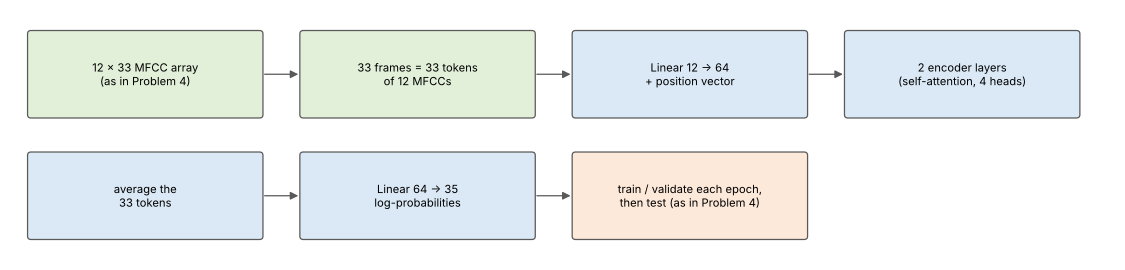

1. **Load** the dataset, labels and MFCC arrays, and build the DataLoaders, as in Problem 4 (Steps 2–5).
2. **Build** the lab notebook's transformer and count its trainable parameters (Step 6).
3. **Train** for 25 epochs with validation after each epoch, **plot** the loss and accuracy curves and **test**
   (Steps 7–11).

### Changes to the Problem 4 notebook
Changed lines are marked `# CHANGED` in the code.
* Model: the lab notebook's `SmallMFCCTransformer` (64-number tokens, learned positions, 2 encoder layers with 4
  attention heads), as written in the lab notebook, instead of the 2-layer Conv2D CNN, with three small changes:
  it reads 12 MFCCs (the lab used 13); it returns log-probabilities, so the training code with `nll_loss` is unchanged
  (log-softmax + negative log-likelihood = the lab's cross-entropy); and it is created with `max_frames=33` (one position
  vector per frame; the lab's default of 128 would add 95 vectors that are never used).
* Optimizer: the lab notebook's AdamW (learning rate 0.001, weight decay 0.0001), which suits transformers better than
  the CNN's learning rate of 0.01.
* Everything else (dataset, labels, MFCC arrays, DataLoaders, schedule, batch size, epochs, `train()`, `test()`, plots,
  test) is the same as in Problem 4.

## Solution

### Step 1: Install torchcodec, imports, versions and device (as in Problems 3–4)

In [ ]:
%pip install -q torchcodec  # torchaudio reads the recordings with torchcodec (as in Problem 3)

In [ ]:
import torch                                 # PyTorch
import torch.nn as nn                        # neural-network layers
import torch.nn.functional as F              # relu, log_softmax, nll_loss, ...
import torch.optim as optim                  # optimizers and learning-rate schedulers
import torchaudio                            # the dataset
import torchcodec                            # decodes the audio files for torchaudio (class notebook)
import numpy as np                           # numerical arrays
import librosa                               # MFCCs, as in Problem 2
from torch.utils.data import TensorDataset, DataLoader  # data sets and loaders built from tensors (lab notebook)

import matplotlib.pyplot as plt              # plotting

In [ ]:
print("torch: ", torch.__version__)          # PyTorch version
print("torchaudio: ", torchaudio.__version__)  # torchaudio version
print("torchcodec: ", torchcodec.__version__)  # torchcodec version
print("librosa: ", librosa.__version__)      # librosa version

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use the GPU when there is one
print(device)                                # cuda or cpu
torch.manual_seed(0)                         # same initial weights and batch order on every run

### Step 2: The dataset (as in Problems 3–4)

In [ ]:
from torchaudio.datasets import SPEECHCOMMANDS                    # the Speech Commands dataset
import os                                                         # file paths

class SubsetSC(SPEECHCOMMANDS):                                   # the class notebook's dataset with the official splits
    def __init__(self, subset: str = None):                        # subset = "training", "validation" or "testing"
        super().__init__("./", download=True)                      # downloads and unpacks the data only if not there yet

        def load_list(filename):                                   # reads one of the official split lists
            filepath = os.path.join(self._path, filename)          # e.g. ./SpeechCommands/.../validation_list.txt
            with open(filepath) as fileobj:                        # open the list
                return [os.path.normpath(os.path.join(self._path, line.strip())) for line in fileobj]  # normpath (as in Problem 3)

        if subset == "validation":                                 # validation files:
            self._walker = load_list("validation_list.txt")        # from the official list
        elif subset == "testing":                                  # test files:
            self._walker = load_list("testing_list.txt")           # from the official list
        elif subset == "training":                                 # training files = all the others
            excludes = load_list("validation_list.txt") + load_list("testing_list.txt")  # files to leave out
            excludes = set(excludes)                               # a set for fast look-up
            self._walker = [w for w in self._walker if os.path.normpath(w) not in excludes]  # normpath (Problem 3)



# Create training, validation and testing splits of the data
train_set = SubsetSC("training")             # training recordings
test_set = SubsetSC("testing")               # test recordings
validation_set = SubsetSC("validation")      # validation recordings (now used after every epoch)

waveform, sample_rate, label, speaker_id, utterance_number = train_set[0]  # the first data point
print("training:", len(train_set), "| validation:", len(validation_set), "| testing:", len(test_set))  # sizes

### Step 3: The labels (label-listing cell disabled, as in Problems 3–4)

In [ ]:
# DISABLED: the class notebook's label-listing cell (it decodes all 84,843 training recordings)
# labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
# labels

In [ ]:
labels = sorted(d for d in os.listdir(train_set._path)          # the labels are the word-folder names,
                if os.path.isdir(os.path.join(train_set._path, d)) and not d.startswith("_"))  # not _background_noise_
labels                                       # the 35 words

### Step 4: MFCC arrays of every 3rd frame (as in Problem 4)
Each recording is cut or padded to 1 s, and `librosa.feature.mfcc` computes 12 MFCCs with the Problem 2 settings
(25 ms Hann frames, 10 ms stride, 40 mel filters), one recording at a time as in Problem 2; every 3rd frame is
kept.
Then each coefficient is scaled to mean 0 and standard deviation 1 using **training** statistics only (as in the lab
notebook; otherwise $c_0$, around −300, would dominate the inputs).

In [ ]:
def label_to_index(word):                    # word -> number 0 ... 34 (as in Problem 3)
    # Return the position of the word in labels
    return torch.tensor(labels.index(word))  # position of the word in labels


def mfcc_arrays(dataset):                                      # 12 MFCCs of every 3rd frame (Problem 4)
    X, y = [], []                                              # MFCC arrays and label numbers
    for i in range(len(dataset)):                              # one recording at a time (as in Problem 2)
        waveform, sample_rate, label, *_ = dataset[i]          # samples (16 kHz), sample rate, word
        w = waveform[0, :16000].numpy()                        # at most 1 s
        w = np.pad(w, (0, 16000 - len(w)))                     # shorter recordings: zeros up to 1 s
        mfcc = librosa.feature.mfcc(y=w, sr=16000, n_mfcc=12,  # Problem 2 settings: 12 MFCCs,
                                    n_fft=400, win_length=400, hop_length=160,  # 25 ms frames every 10 ms,
                                    window="hann", center=False, n_mels=40)    # Hann window, 40 mel filters
        X.append(mfcc[:, ::3])                                 # every 3rd frame -> [12, 33]
        y.append(label_to_index(label))                        # label number
    return torch.tensor(np.stack(X)).unsqueeze(1), torch.stack(y)  # [N, 1, 12, 33] and [N]


X_train, y_train = mfcc_arrays(train_set)                      # training arrays
X_val, y_val = mfcc_arrays(validation_set)                     # validation arrays
X_test, y_test = mfcc_arrays(test_set)                         # test arrays

mean = X_train.mean(dim=(0, 3), keepdim=True)                  # mean of each coefficient (training data only)
std = X_train.std(dim=(0, 3), keepdim=True)                    # standard deviation of each coefficient
X_train, X_val, X_test = [(X - mean) / std for X in (X_train, X_val, X_test)]  # same scaling for all three sets
print("MFCC arrays [recordings, channel, MFCCs, frames]:",   # shapes of the three sets
      tuple(X_train.shape), tuple(X_val.shape), tuple(X_test.shape))  # training, validation, test

### Step 5: DataLoaders for training, validation and testing (as in Problem 4)

In [ ]:
batch_size = 256                             # recordings per batch (as in Problems 3-4)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)  # from the arrays (Problem 4)
validation_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)              # validation (Problem 4)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size)                  # test (Problem 4)

### Step 6: The transformer (lab notebook)
Each frame (12 MFCCs) is projected to a 64-number token and a learned position vector is added. Two transformer encoder
layers (4 attention heads each) let every frame look at all the others. The tokens are averaged and a linear layer gives
the 35 word scores.

In [ ]:
class SmallMFCCTransformer(nn.Module):                         # the lab notebook's transformer
    def __init__(                                              # its settings:
        self,                                                  # the model
        n_classes=35,                                          # 35 words out
        max_frames=128,                                        # at most 128 frames (here created with 33)
        d_model=64,                                            # tokens of 64 numbers
        nhead=4,                                               # 4 attention heads
        num_layers=2,                                          # 2 encoder layers
    ):                                                         # end of the settings
        super().__init__()                                     # set up the nn.Module

        if d_model % nhead != 0:                               # each head gets d_model / nhead numbers
            raise ValueError("d_model must be divisible by nhead.")  # so they must divide evenly

        self.projection = nn.Linear(12, d_model)               # CHANGED (lab: 13): each frame's 12 MFCCs -> 64 numbers

        self.position = nn.Parameter(                          # one learned position vector per frame
            torch.zeros(1, max_frames, d_model)                # [1, frames, 64]
        )                                                      # end of the parameter
        nn.init.normal_(self.position, std=0.02)               # small random starting values

        self.blocks = nn.ModuleList([                          # the encoder layers:
            nn.TransformerEncoderLayer(                        # one layer =
                d_model=d_model,                               # tokens of 64 numbers,
                nhead=nhead,                                   # self-attention with 4 heads,
                dim_feedforward=128,                           # a feed-forward network with 128 units,
                dropout=0.1,                                   # dropout 0.1,
                activation="gelu",                             # GELU activation,
                batch_first=True,                              # input [batch, frames, 64]
            )                                                  # end of one layer
            for _ in range(num_layers)                         # 2 independent layers
        ])                                                     # end of the list

        self.norm = nn.LayerNorm(d_model)                      # layer normalization at the end
        self.head = nn.Linear(d_model, n_classes)              # 64 -> 35 word scores

    def forward(self, x):                                      # x: [batch, 1, 12, frames]
        if x.ndim != 4 or x.shape[1] != 1 or x.shape[2] != 12:  # CHANGED (lab: 13): check the input shape
            raise ValueError(                                  # explain a wrong input
                "Expected input [batch, 1, 12, frames], "      # CHANGED (lab: 13)
                f"got {tuple(x.shape)}."                       # the shape that was given
            )                                                  # end of the error

        # [B, 1, 12, T] -> [B, T, 12]
        x = x.squeeze(1).transpose(1, 2)                       # frames become the sequence

        frames = x.shape[1]                                    # number of frames (33)
        if frames > self.position.shape[1]:                    # more frames than position vectors?
            raise ValueError(                                  # explain the problem
                f"Input has {frames} frames, but max_frames="  # how many frames
                f"{self.position.shape[1]}. "                  # versus position vectors
                "Recreate the model with a larger max_frames."  # how to fix it
            )                                                  # end of the error

        x = self.projection(x) + self.position[:, :frames]     # tokens + positions -> [batch, 33, 64]

        for block in self.blocks:                              # the two encoder layers
            x = block(x)                                       # self-attention + feed-forward

        x = self.norm(x).mean(dim=1)                           # average over the frames -> [batch, 64]
        return F.log_softmax(self.head(x), dim=1)              # CHANGED (lab: logits): log-probabilities for nll_loss


model = SmallMFCCTransformer(n_classes=len(labels), max_frames=33)  # CHANGED: the transformer, one position per frame
model.to(device)                                               # move the model to the GPU/CPU
print(model)                                                   # show the layers


def count_parameters(model):                                   # number of trainable parameters (as in Problems 3-4)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)  # add up the sizes of all weights


n = count_parameters(model)                                    # count them
print("Number of trainable parameters: %s" % n)               # 72,291

### Step 7: Optimizer (lab notebook)

In [ ]:
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)  # CHANGED: the lab notebook's optimizer
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)  # reduce the learning after 20 epochs by a factor of 10

### Step 8: Training and testing functions (as in Problem 4)

In [ ]:
def train(model, epoch, log_interval):                         # one epoch on the training set
    model.train()                                              # training mode (batch norm uses batch statistics)
    total_loss, correct = 0.0, 0                               # sums for the epoch's average loss and accuracy
    for batch_idx, (data, target) in enumerate(train_loader):  # one batch at a time

        data = data.to(device)                                 # move the inputs to the GPU/CPU
        target = target.to(device)                             # and the labels

        output = model(data)                                   # run the model on the MFCC arrays

        # negative log-likelihood
        loss = F.nll_loss(output.squeeze(), target)            # the loss of this batch

        optimizer.zero_grad()                                  # clear the old gradients
        loss.backward()                                        # backpropagation
        optimizer.step()                                       # update the weights

        # print training stats
        if batch_idx % log_interval == 0:                      # every log_interval batches
            print(f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(train_loader.dataset)} ({100. * batch_idx / len(train_loader):.0f}%)]\tLoss: {loss.item():.6f}")  # progress

        # record loss
        losses.append(loss.item())                             # loss of every batch (class notebook)
        total_loss += loss.item() * len(target)                # add up the loss of this batch
        correct += number_of_correct(get_likely_index(output), target)  # and its correct predictions

    return total_loss / len(train_loader.dataset), correct / len(train_loader.dataset)  # epoch averages

In [ ]:
def number_of_correct(pred, target):         # number of correct predictions
    # count number of correct predictions
    return pred.squeeze().eq(target).sum().item()  # compare predicted and true labels


def get_likely_index(tensor):                # most likely word for each recording
    # find most likely label index for each element in the batch
    return tensor.argmax(dim=-1)             # index of the largest log-probability


def test(model, epoch, loader=test_loader, name="Test"):       # as in Problem 3: data set to use, and its name
    model.eval()                                               # evaluation mode (batch norm uses stored statistics)
    correct = 0                                                # correct predictions
    total_loss = 0.0                                           # summed loss
    with torch.no_grad():                                      # no gradients needed for evaluation
        for data, target in loader:                            # one batch at a time (as in Problem 3)

            data = data.to(device)                             # move the inputs to the GPU/CPU
            target = target.to(device)                         # and the labels

            output = model(data)                               # run the model

            pred = get_likely_index(output)                    # predicted words
            correct += number_of_correct(pred, target)         # count the correct ones
            total_loss += F.nll_loss(output.squeeze(), target, reduction="sum").item()  # summed loss

    print(f"{name} Epoch: {epoch}\tAccuracy: {correct}/{len(loader.dataset)} ({100. * correct / len(loader.dataset):.1f}%)\tLoss: {total_loss / len(loader.dataset):.3f}")  # result
    return total_loss / len(loader.dataset), correct / len(loader.dataset)  # average loss and accuracy

### Step 9: Train, validating at the end of every epoch (25 epochs, as in Problems 3–4)

In [ ]:
log_interval = 100                           # print the training loss every 100 batches (as in Problems 3-4)
n_epoch = 25                                 # number of epochs (as in Problems 3-4)

losses = []                                  # loss of every training batch (class notebook)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # one value per epoch

for epoch in range(1, n_epoch + 1):          # one epoch at a time
    train_loss, train_acc = train(model, epoch, log_interval)                   # train on all training recordings
    val_loss, val_acc = test(model, epoch, validation_loader, "Validation")     # validate the current model
    scheduler.step()                         # learning-rate schedule
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):  # store the four numbers
        history[key].append(value)           # of this epoch

### Step 10: Accuracy and loss curves (as in Problems 3–4)

In [ ]:
epochs = range(1, n_epoch + 1)                                 # x axis: epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                # two diagrams side by side
ax[0].plot(epochs, history["train_acc"], "o-", label="training")      # training accuracy
ax[0].plot(epochs, history["val_acc"], "s-", label="validation")      # validation accuracy
ax[0].set_title("Accuracy")                                    # first diagram: accuracy
ax[0].set_ylabel("accuracy")                                   # vertical axis label
ax[1].plot(epochs, history["train_loss"], "o-", label="training")     # training loss
ax[1].plot(epochs, history["val_loss"], "s-", label="validation")     # validation loss
ax[1].set_title("Loss (negative log-likelihood)")              # second diagram: loss
ax[1].set_ylabel("loss")                                       # vertical axis label
for axis in ax:                                                # common settings
    axis.set_xlabel("epoch")                                   # horizontal axis label
    axis.set_xticks(list(epochs))                              # one tick per epoch
    axis.grid(alpha=0.3)                                       # light grid
    axis.legend()                                              # training vs validation
plt.tight_layout()                                             # avoid overlapping labels
plt.show()                                                     # render the figure

### Step 11: Accuracy on the test set

In [ ]:
test_loss, test_acc = test(model, n_epoch, test_loader, "Test")  # the final model on the 11,005 test recordings

---
# Appendix: The ideas behind Problem 5

## A.1 Frames become tokens, and self-attention compares them
The transformer treats the 33 kept frames like the words of a sentence: each frame's 12 MFCCs are projected to a token of
64 numbers, and a learned position vector tells the model where in the recording the frame is. In each encoder layer,
**self-attention** lets every token look at all 33 tokens: for each pair it computes a weight (how relevant the other
frame is), and the token is updated with the weighted average of the others. With 4 heads, this is done 4 times in
parallel with different weights. A feed-forward network then processes each token on its own.

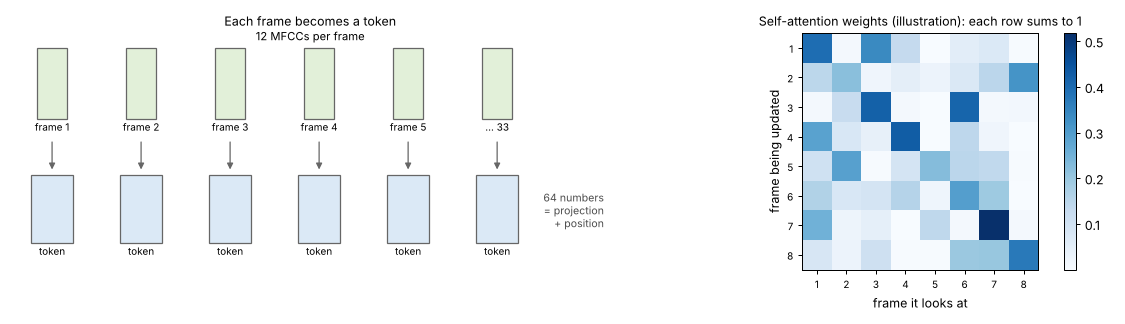

Unlike the CNN, whose 3 × 3 filters only see neighboring frames, attention can connect frames that are far apart (for
example the beginning and the end of a word) in a single layer.

## A.2 Counting the trainable parameters

| Part | Count | Parameters |
|---|---|---|
| Projection 12 → 64 | 12·64 weights + 64 biases | 832 |
| Position vectors | 33 frames × 64 | 2,112 |
| Encoder layer: attention | 3·(64·64 + 64) for queries, keys, values + (64·64 + 64) output | 16,640 |
| Encoder layer: feed-forward | (64·128 + 128) + (128·64 + 64) | 16,576 |
| Encoder layer: 2 layer norms | 2 × (64 + 64) | 256 |
| 2 encoder layers | 2 × 33,472 | 66,944 |
| Final layer norm | 64 + 64 | 128 |
| Head 64 → 35 | 64·35 weights + 35 biases | 2,275 |
| **Total** | | **72,291** |

Most parameters are in the two encoder layers; the model is about 3.4 times as large as the CNN of Problem 4 (21,283).